# Multi-Type Document Image Classification + OCR Demonstration

This notebook adapts the supplied PCB notebook's five-model comparison to the **OCR Dataset of Multi-type Documents**.

**Important dataset limitation:** the linked dataset is organized by document category (commonly ADVE, Email, Form, Letter, Memo, News, Note, Report, Resume, Scientific). Its labels support **document-image classification**. It does not provide verified text transcriptions for training an OCR recognition model. The OCR section below runs Tesseract on sample images as an extraction demonstration; it does not train/evaluate OCR accuracy.

The five architectures retained from the reference project are CNN, RNN, LSTM, Bi-LSTM and GNN. The number of output classes is inferred from the dataset folders.


## 1. Install / import dependencies

In [2]:
# In Google Colab or Kaggle, uncomment if a package is missing:
# !pip -q install torch torchvision scikit-learn pandas matplotlib seaborn pillow pytesseract

import os, random, time, json, copy, glob, subprocess, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageEnhance

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


## 2. Locate the extracted dataset

In [3]:
# Kaggle: attach the dataset using Add Input. Colab/local: set DATA_ROOT manually.
POSSIBLE_ROOTS = [
    Path("/kaggle/input/ocr-dataset-of-multi-type-documents"),
    Path("/kaggle/input"),
    Path("/content"),
    Path("./data"),
    Path(".")
]
DATA_ROOT = None

# Find a directory that ImageFolder can read (at least two class subfolders with images).
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def is_imagefolder_root(p):
    if not p.is_dir(): return False
    class_dirs = [x for x in p.iterdir() if x.is_dir()]
    valid = 0
    for d in class_dirs:
        if any(f.suffix.lower() in IMAGE_EXTS for f in d.rglob("*") if f.is_file()):
            valid += 1
    return valid >= 2

for base in POSSIBLE_ROOTS:
    if base.exists():
        candidates = [base] + [p for p in base.rglob("*") if p.is_dir()]
        for candidate in candidates:
            if is_imagefolder_root(candidate):
                DATA_ROOT = candidate
                break
    if DATA_ROOT is not None: break

if DATA_ROOT is None:
    raise FileNotFoundError(
        "Could not find class folders. Set DATA_ROOT to the directory whose immediate "
        "subfolders are document classes (e.g. Email, Form, Letter, ...)."
    )

print("Dataset root:", DATA_ROOT)
for d in sorted([x for x in DATA_ROOT.iterdir() if x.is_dir()]):
    n = sum(1 for f in d.rglob("*") if f.is_file() and f.suffix.lower() in IMAGE_EXTS)
    if n: print(f"{d.name}: {n} images")


Dataset root: /kaggle/input/datasets/senju14/ocr-dataset-of-multi-type-documents
document: 1539 images
form: 199 images
invoice: 973 images
real_life: 1554 images


## 3. Read images and inspect class distribution

Classes: ['document', 'form', 'invoice', 'real_life']
Total images: 4265 | Number of classes: 4


,images
real_life,1554
document,1539
invoice,973
form,199


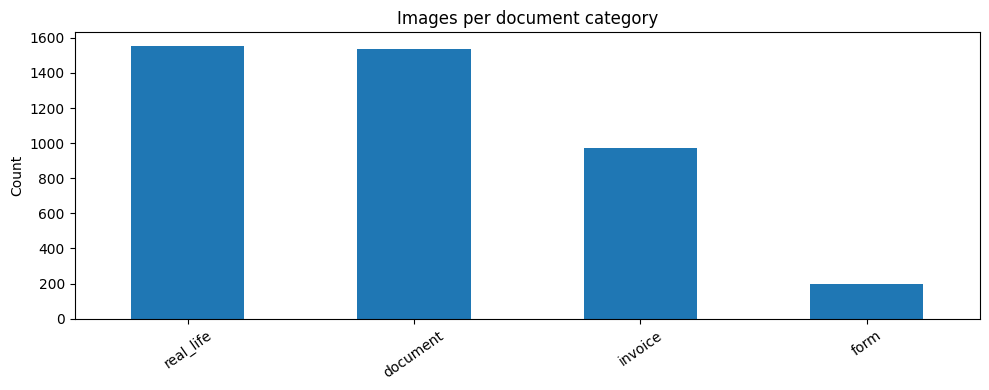

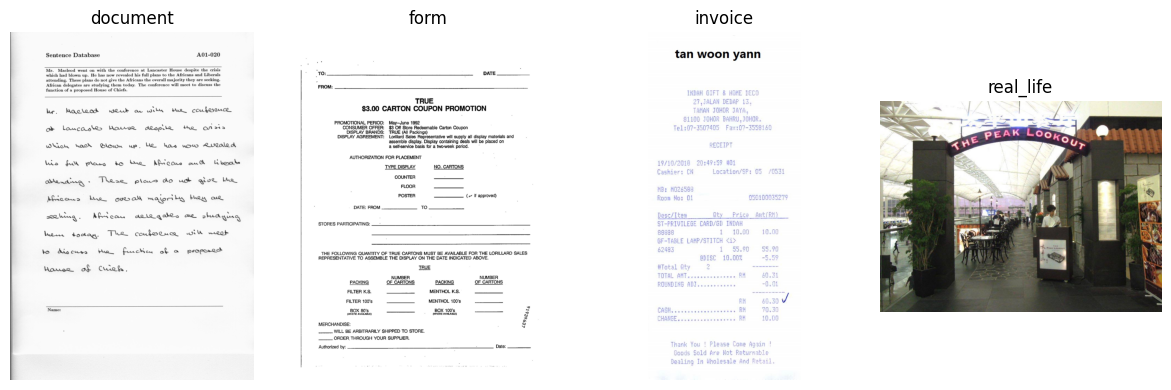

In [4]:
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 2 if os.name != "nt" else 0

base_dataset = datasets.ImageFolder(str(DATA_ROOT))
CLASS_NAMES = base_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)
targets = np.array(base_dataset.targets)
indices = np.arange(len(base_dataset))

print("Classes:", CLASS_NAMES)
print("Total images:", len(base_dataset), "| Number of classes:", NUM_CLASSES)
display(pd.Series(targets).map(dict(enumerate(CLASS_NAMES))).value_counts().rename("images").to_frame())

plt.figure(figsize=(10,4))
pd.Series(targets).map(dict(enumerate(CLASS_NAMES))).value_counts().plot(kind="bar")
plt.title("Images per document category"); plt.ylabel("Count"); plt.xticks(rotation=35)
plt.tight_layout(); plt.show()

# Show a sample image from each class
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(3*NUM_CLASSES, 4))
if NUM_CLASSES == 1: axes = [axes]
for cls_idx, ax in enumerate(axes):
    sample_idx = next(i for i, y in enumerate(targets) if y == cls_idx)
    img, label = base_dataset[sample_idx]
    ax.imshow(img); ax.set_title(CLASS_NAMES[label]); ax.axis("off")
plt.tight_layout(); plt.show()


## 4. Stratified train / validation / test split

In [5]:
# This dataset is normally arranged by class folders and may not include board/document IDs.
# We therefore use a stratified image-level split. If near-duplicate pages exist, group them
# before splitting to avoid leakage.
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=targets
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=SEED, stratify=targets[temp_idx]
)

print("Train:", len(train_idx), "Validation:", len(val_idx), "Test:", len(test_idx))


Train: 2985 Validation: 640 Test: 640


## 5. Image transforms and data loaders

In [6]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(3),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406], [0.229,0.224,0.225])
])

class TransformSubset(Dataset):
    def __init__(self, imagefolder, indices, transform):
        self.dataset = imagefolder
        self.indices = list(indices)
        self.transform = transform
    def __len__(self): return len(self.indices)
    def __getitem__(self, i):
        path, label = self.dataset.samples[self.indices[i]]
        image = Image.open(path).convert("RGB")
        return self.transform(image), int(label)

train_ds = TransformSubset(base_dataset, train_idx, train_transform)
train_eval_ds = TransformSubset(base_dataset, train_idx, eval_transform)
val_ds = TransformSubset(base_dataset, val_idx, eval_transform)
test_ds = TransformSubset(base_dataset, test_idx, eval_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
train_eval_loader = DataLoader(train_eval_ds, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))


## 6. CNN, RNN, LSTM, Bi-LSTM and GNN architectures

In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, pool=True):
        super().__init__()
        layers = [nn.Conv2d(in_ch,out_ch,3,padding=1,bias=False),
                  nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
                  nn.Conv2d(out_ch,out_ch,3,padding=1,bias=False),
                  nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True)]
        if pool: layers.append(nn.MaxPool2d(2))
        self.block = nn.Sequential(*layers)
    def forward(self,x): return self.block(x)

class DocumentEncoder(nn.Module):
    def __init__(self, feature_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            ConvBlock(3,32), ConvBlock(32,64), ConvBlock(64,128),
            nn.AdaptiveAvgPool2d((7,7))
        )
        self.proj = nn.Conv2d(128, feature_dim, kernel_size=1)
    def forward(self,x): return self.proj(self.net(x))

class CNNClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.encoder = DocumentEncoder()
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                   nn.Dropout(0.35), nn.Linear(128,num_classes))
    def forward(self,x): return self.head(self.encoder(x))

class SequenceClassifier(nn.Module):
    def __init__(self, kind, num_classes, hidden=128):
        super().__init__()
        self.encoder = DocumentEncoder()
        if kind == "rnn":
            self.sequence = nn.RNN(128, hidden, batch_first=True)
            out_dim = hidden
        elif kind == "lstm":
            self.sequence = nn.LSTM(128, hidden, batch_first=True)
            out_dim = hidden
        elif kind == "bilstm":
            self.sequence = nn.LSTM(128, hidden, batch_first=True, bidirectional=True)
            out_dim = hidden*2
        else: raise ValueError(kind)
        self.head = nn.Sequential(nn.Dropout(0.4), nn.Linear(out_dim,num_classes))
    def forward(self,x):
        fmap = self.encoder(x)
        seq = fmap.flatten(2).transpose(1,2)  # batch x 49 spatial tokens x 128
        out = self.sequence(seq)
        seq_out = out[0] if isinstance(out, tuple) else out
        return self.head(seq_out[:,-1,:])

class GridGraphConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.self_linear = nn.Linear(in_dim,out_dim)
        self.neigh_linear = nn.Linear(in_dim,out_dim)
    def forward(self,x,adj):
        return F.relu(self.self_linear(x) + self.neigh_linear(torch.matmul(adj,x)))

def make_grid_adjacency(side=7):
    n = side*side
    A = torch.zeros(n,n)
    for r in range(side):
        for c in range(side):
            i = r*side+c
            A[i,i] = 1
            for dr,dc in [(-1,0),(1,0),(0,-1),(0,1)]:
                rr,cc=r+dr,c+dc
                if 0 <= rr < side and 0 <= cc < side: A[i,rr*side+cc] = 1
    return A / A.sum(dim=1,keepdim=True).clamp_min(1)

class GNNClassifier(nn.Module):
    def __init__(self,num_classes):
        super().__init__()
        self.encoder = DocumentEncoder()
        self.register_buffer("adj", make_grid_adjacency(7))
        self.g1 = GridGraphConv(128,128); self.g2 = GridGraphConv(128,128)
        self.head = nn.Sequential(nn.Dropout(0.4),nn.Linear(128,num_classes))
    def forward(self,x):
        nodes = self.encoder(x).flatten(2).transpose(1,2)
        h = self.g2(self.g1(nodes,self.adj),self.adj)
        return self.head(h.mean(dim=1))

MODEL_NAMES = ["cnn","rnn","lstm","bilstm","gnn"]
def build_model(name):
    if name == "cnn": return CNNClassifier(NUM_CLASSES)
    if name in ("rnn","lstm","bilstm"): return SequenceClassifier(name,NUM_CLASSES)
    if name == "gnn": return GNNClassifier(NUM_CLASSES)
    raise ValueError(name)


## 7. Training utilities

In [8]:
EPOCHS = 20
PATIENCE = 5
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
RESULT_DIR = Path("./document_classification_results")
CKPT_DIR = RESULT_DIR / "checkpoints"
CKPT_DIR.mkdir(parents=True, exist_ok=True)

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, ys, preds = 0.0, [], []
    for xb,yb in loader:
        xb,yb = xb.to(DEVICE), yb.to(DEVICE)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(xb); loss = criterion(logits,yb)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),5.0)
                optimizer.step()
        total_loss += loss.item()*len(yb)
        ys.extend(yb.detach().cpu().numpy())
        preds.extend(logits.argmax(1).detach().cpu().numpy())
    return total_loss/len(loader.dataset), accuracy_score(ys,preds), np.array(ys), np.array(preds)

def train_model(model_name):
    model = build_model(model_name).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,mode="min",factor=0.5,patience=2
    )
    best_val_loss = float("inf"); best_epoch = 0; patience_count = 0
    history = []; checkpoint_path = CKPT_DIR / f"best_{model_name}.pth"
    start = time.time()

    for epoch in range(1,EPOCHS+1):
        tr_loss,tr_acc,_,_ = run_epoch(model,train_loader,criterion,optimizer)
        va_loss,va_acc,_,_ = run_epoch(model,val_loader,criterion)
        scheduler.step(va_loss)
        history.append({"epoch":epoch,"train_loss":tr_loss,"train_accuracy":tr_acc,
                        "val_loss":va_loss,"val_accuracy":va_acc})
        print(f"{model_name} {epoch}/{EPOCHS} | train acc={tr_acc:.4f} "
              f"| val acc={va_acc:.4f} | val loss={va_loss:.4f}")
        if va_loss < best_val_loss:
            best_val_loss = va_loss; best_epoch = epoch; patience_count = 0
            torch.save({"model_state":model.state_dict(),"class_names":CLASS_NAMES,
                        "epoch":epoch},checkpoint_path)
        else:
            patience_count += 1
            if patience_count >= PATIENCE:
                print("Early stopping"); break

    hist = pd.DataFrame(history)
    hist.to_csv(RESULT_DIR/f"history_{model_name}.csv",index=False)
    return {"model":model_name,"best_epoch":best_epoch,"best_val_loss":best_val_loss,
            "training_seconds":time.time()-start,"history":hist}

def load_model_checkpoint(name):
    model = build_model(name).to(DEVICE)
    ckpt = torch.load(CKPT_DIR/f"best_{name}.pth",map_location=DEVICE)
    model.load_state_dict(ckpt["model_state"])
    return model


In [9]:
training_results = []; histories = {}
for model_name in MODEL_NAMES:
    print("\\n"+"="*60+"\\nTRAINING "+model_name.upper()+"\\n"+"="*60)
    result = train_model(model_name)
    training_results.append({k:v for k,v in result.items() if k!="history"})
    histories[model_name] = result["history"]

training_summary = pd.DataFrame(training_results)
display(training_summary)
training_summary.to_csv(RESULT_DIR/"training_summary.csv",index=False)


\n============================================================\nTRAINING CNN\n============================================================
cnn 1/20 | train acc=0.8824 | val acc=0.9906 | val loss=0.0646
cnn 2/20 | train acc=0.9688 | val acc=0.9156 | val loss=0.2918
cnn 3/20 | train acc=0.9762 | val acc=0.9437 | val loss=0.1721
cnn 4/20 | train acc=0.9832 | val acc=0.9953 | val loss=0.0180
cnn 5/20 | train acc=0.9843 | val acc=0.9938 | val loss=0.0263
cnn 6/20 | train acc=0.9899 | val acc=0.9953 | val loss=0.0172
cnn 7/20 | train acc=0.9899 | val acc=0.8984 | val loss=0.4298
cnn 8/20 | train acc=0.9926 | val acc=0.9906 | val loss=0.0278
cnn 9/20 | train acc=0.9946 | val acc=0.9531 | val loss=0.0948
cnn 10/20 | train acc=0.9936 | val acc=0.9969 | val loss=0.0058
cnn 11/20 | train acc=0.9973 | val acc=0.9953 | val loss=0.0107
cnn 12/20 | train acc=0.9960 | val acc=0.9969 | val loss=0.0066
cnn 13/20 | train acc=0.9970 | val acc=0.9969 | val loss=0.0102
cnn 14/20 | train acc=0.9977 | val acc

,model,best_epoch,best_val_loss,training_seconds
0,cnn,16,0.001340,2971.657435
1,rnn,17,0.013104,2802.480794
2,lstm,13,0.008112,2497.101405
3,bilstm,16,0.004067,2784.369983
4,gnn,10,0.003720,2094.355390


## 8. Train all five models

## 9. Learning curves

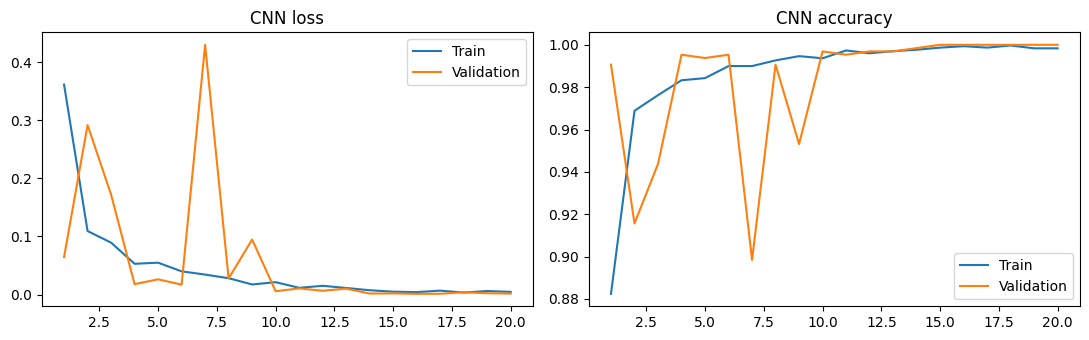

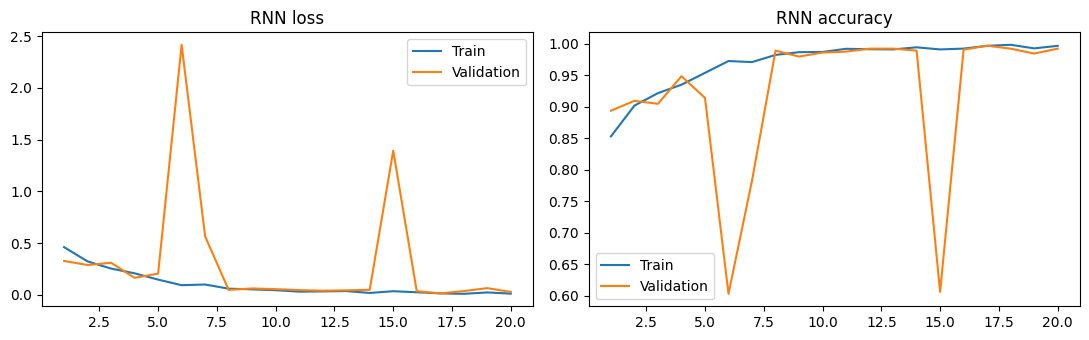

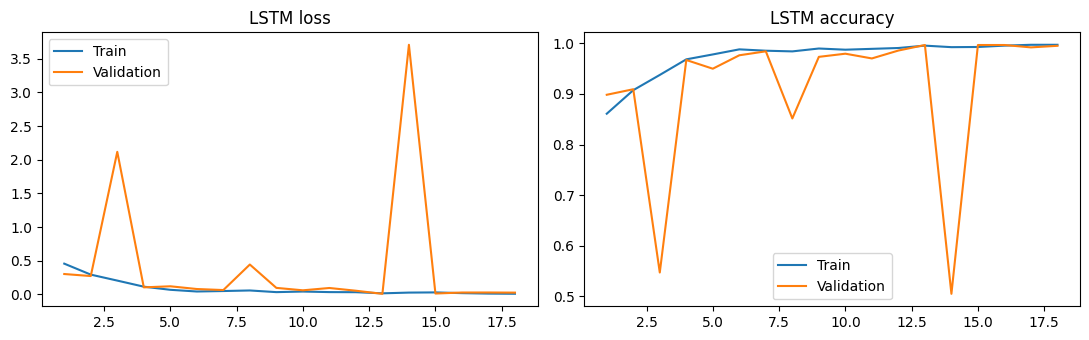

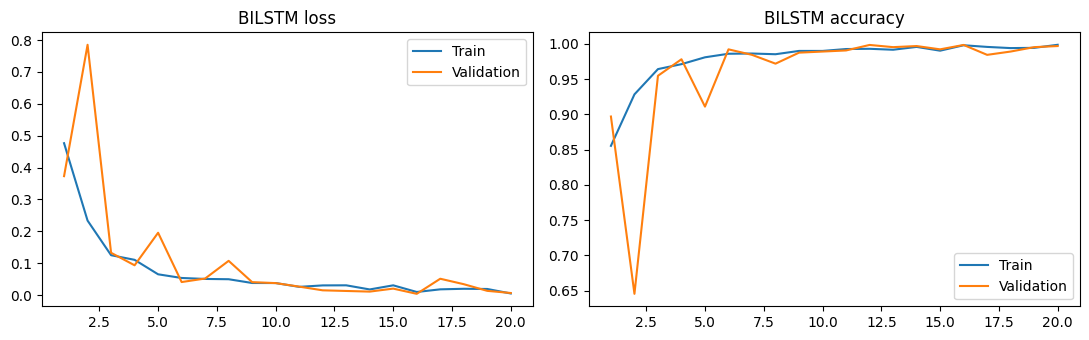

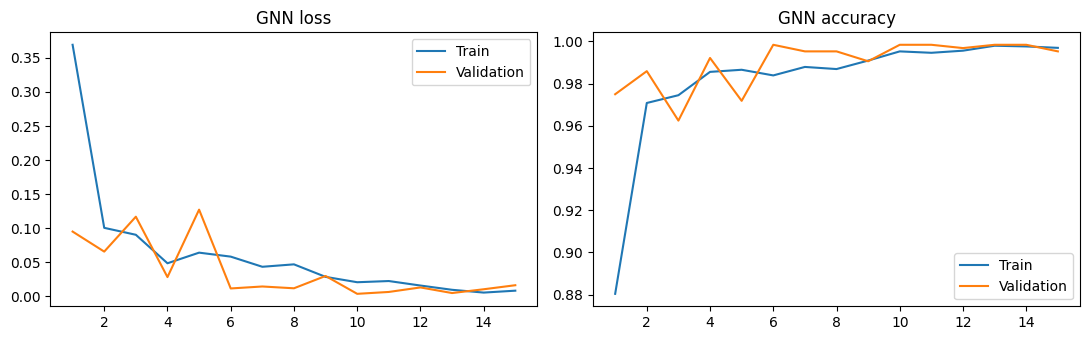

In [10]:
for name,hist in histories.items():
    fig,axes = plt.subplots(1,2,figsize=(11,3.5))
    axes[0].plot(hist.epoch,hist.train_loss,label="Train")
    axes[0].plot(hist.epoch,hist.val_loss,label="Validation")
    axes[0].set_title(f"{name.upper()} loss"); axes[0].legend()
    axes[1].plot(hist.epoch,hist.train_accuracy,label="Train")
    axes[1].plot(hist.epoch,hist.val_accuracy,label="Validation")
    axes[1].set_title(f"{name.upper()} accuracy"); axes[1].legend()
    plt.tight_layout(); plt.show()


## 10. Select best model using validation macro-F1

In [11]:
def collect_predictions(model,loader):
    model.eval(); ys=[]; preds=[]; probs=[]
    with torch.no_grad():
        for xb,yb in loader:
            logits=model(xb.to(DEVICE))
            p=torch.softmax(logits,dim=1).cpu().numpy()
            probs.extend(p); preds.extend(p.argmax(axis=1)); ys.extend(yb.numpy())
    return np.array(ys),np.array(preds),np.array(probs)

validation_rows=[]
for name in MODEL_NAMES:
    model=load_model_checkpoint(name)
    y_true,y_pred,_=collect_predictions(model,val_loader)
    p,r,f1,_=precision_recall_fscore_support(
        y_true,y_pred,labels=list(range(NUM_CLASSES)),average="macro",zero_division=0
    )
    validation_rows.append({"model":name,"val_accuracy":accuracy_score(y_true,y_pred),
                            "val_macro_precision":p,"val_macro_recall":r,"val_macro_f1":f1})
validation_df=pd.DataFrame(validation_rows).sort_values(
    ["val_macro_f1","val_accuracy"],ascending=False
)
display(validation_df)
validation_df.to_csv(RESULT_DIR/"validation_model_comparison.csv",index=False)
BEST_MODEL_NAME=validation_df.iloc[0].model
print("Selected model:",BEST_MODEL_NAME)


,model,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1
0,cnn,1.000000,1.000000,1.000000,1.000000
3,bilstm,0.998437,0.998922,0.991667,0.995223
4,gnn,0.998437,0.998299,0.991667,0.994909
2,lstm,0.996875,0.990235,0.997835,0.993961
1,rnn,0.996875,0.990598,0.989954,0.990272


Selected model: cnn


## 11. Final held-out test evaluation

In [12]:
test_rows=[]; test_outputs={}
for name in MODEL_NAMES:
    model=load_model_checkpoint(name)
    y_true,y_pred,y_prob=collect_predictions(model,test_loader)
    test_outputs[name]=(y_true,y_pred,y_prob)
    p,r,f1,_=precision_recall_fscore_support(
        y_true,y_pred,labels=list(range(NUM_CLASSES)),average="macro",zero_division=0
    )
    test_rows.append({"model":name,"test_accuracy":accuracy_score(y_true,y_pred),
                      "test_macro_precision":p,"test_macro_recall":r,"test_macro_f1":f1})
    print("\\n",name.upper())
    print(classification_report(y_true,y_pred,labels=list(range(NUM_CLASSES)),
                                target_names=CLASS_NAMES,zero_division=0))
test_df=pd.DataFrame(test_rows).sort_values("test_macro_f1",ascending=False)
display(test_df)
test_df.to_csv(RESULT_DIR/"test_model_comparison.csv",index=False)


\n CNN
              precision    recall  f1-score   support

    document       1.00      1.00      1.00       231
        form       1.00      1.00      1.00        30
     invoice       1.00      1.00      1.00       146
   real_life       1.00      1.00      1.00       233

    accuracy                           1.00       640
   macro avg       1.00      1.00      1.00       640
weighted avg       1.00      1.00      1.00       640

\n RNN
              precision    recall  f1-score   support

    document       0.99      0.99      0.99       231
        form       0.97      0.97      0.97        30
     invoice       0.99      0.99      0.99       146
   real_life       1.00      1.00      1.00       233

    accuracy                           0.99       640
   macro avg       0.99      0.99      0.99       640
weighted avg       0.99      0.99      0.99       640

\n LSTM
              precision    recall  f1-score   support

    document       1.00      0.99      0.99       231

,model,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1
0,cnn,1.000000,1.000000,1.000000,1.000000
4,gnn,1.000000,1.000000,1.000000,1.000000
3,bilstm,0.995313,0.994966,0.989502,0.992133
2,lstm,0.993750,0.993845,0.987790,0.990734
1,rnn,0.992188,0.986078,0.986078,0.986078


## 12. Confusion matrices and per-class metrics

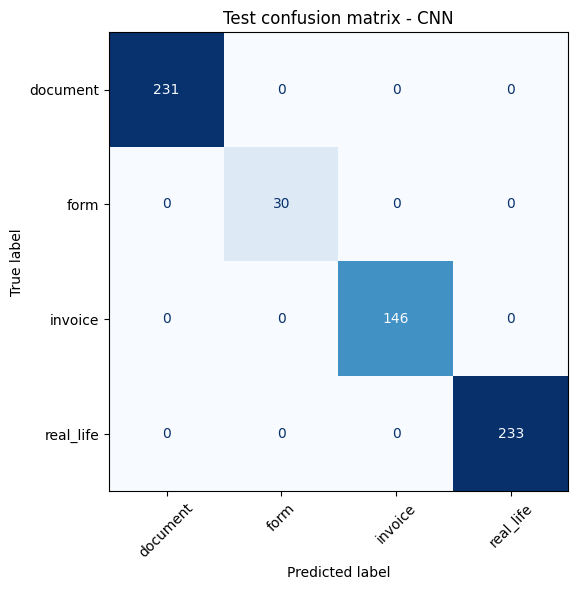

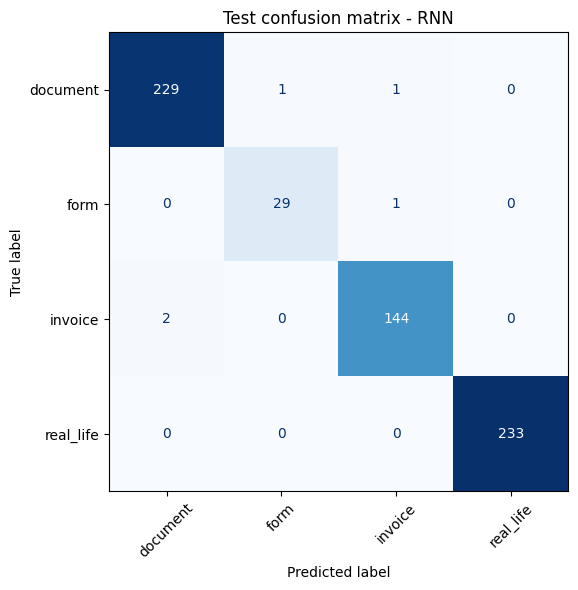

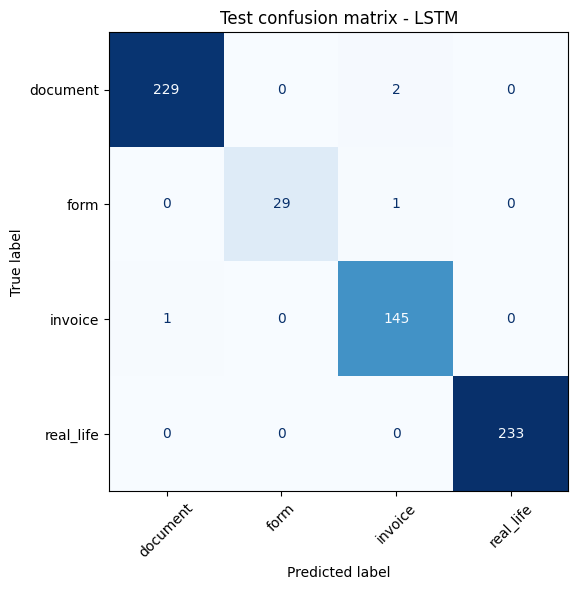

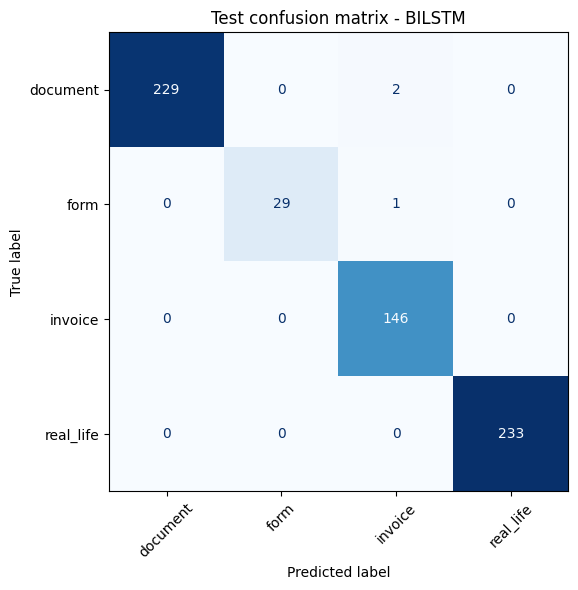

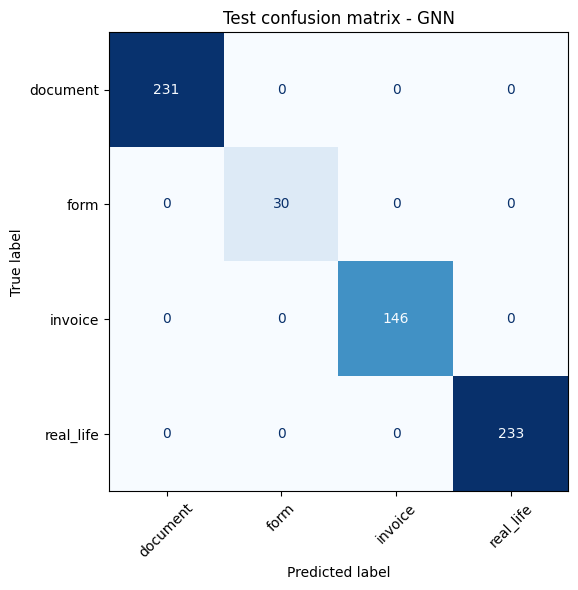

,model,class,precision,recall,f1,support
0,cnn,document,1.000000,1.000000,1.000000,231
1,cnn,form,1.000000,1.000000,1.000000,30
2,cnn,invoice,1.000000,1.000000,1.000000,146
3,cnn,real_life,1.000000,1.000000,1.000000,233
4,rnn,document,0.991342,0.991342,0.991342,231
5,rnn,form,0.966667,0.966667,0.966667,30
6,rnn,invoice,0.986301,0.986301,0.986301,146
7,rnn,real_life,1.000000,1.000000,1.000000,233
8,lstm,document,0.995652,0.991342,0.993492,231
9,lstm,form,1.000000,0.966667,0.983051,30


In [13]:
for name,(y_true,y_pred,_) in test_outputs.items():
    cm=confusion_matrix(y_true,y_pred,labels=list(range(NUM_CLASSES)))
    disp=ConfusionMatrixDisplay(cm,display_labels=CLASS_NAMES)
    fig,ax=plt.subplots(figsize=(max(7,NUM_CLASSES),6))
    disp.plot(ax=ax,xticks_rotation=45,colorbar=False,cmap="Blues")
    ax.set_title(f"Test confusion matrix - {name.upper()}")
    plt.tight_layout(); plt.show()
    pd.DataFrame(cm,index=CLASS_NAMES,columns=CLASS_NAMES).to_csv(
        RESULT_DIR/f"confusion_matrix_{name}.csv"
    )

per_class_rows=[]
for name,(y_true,y_pred,_) in test_outputs.items():
    p,r,f1,s=precision_recall_fscore_support(
        y_true,y_pred,labels=list(range(NUM_CLASSES)),average=None,zero_division=0
    )
    for i,cls in enumerate(CLASS_NAMES):
        per_class_rows.append({"model":name,"class":cls,"precision":p[i],
                               "recall":r[i],"f1":f1[i],"support":s[i]})
per_class_df=pd.DataFrame(per_class_rows)
display(per_class_df)
per_class_df.to_csv(RESULT_DIR/"per_class_test_metrics.csv",index=False)


## 13. OCR extraction demonstration with Tesseract (not OCR model training)

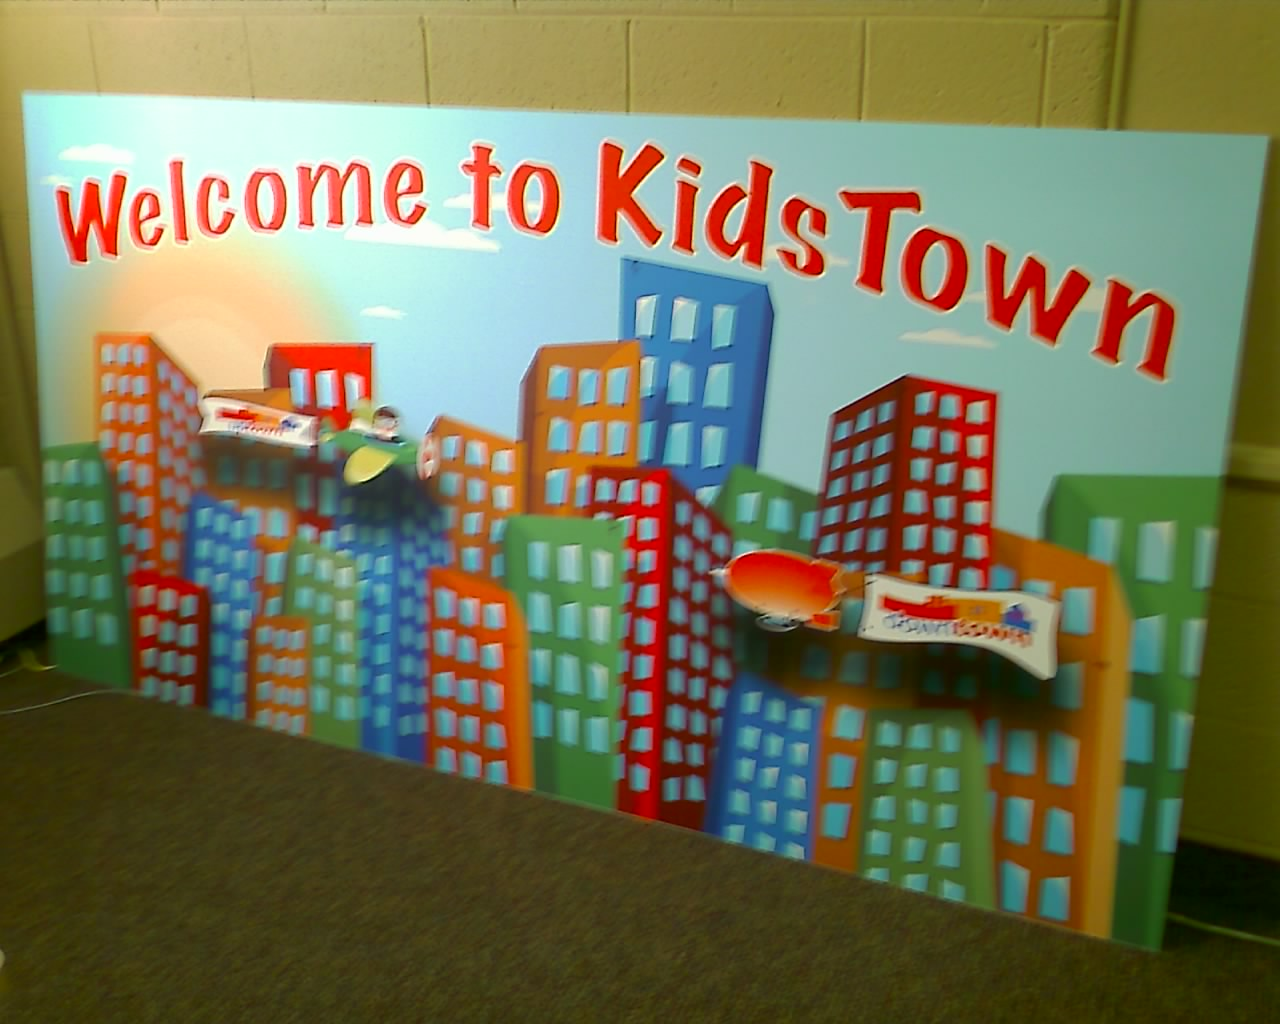

Actual document category: real_life
OCR extracted text:\n
; a # ©
: ‘olde i
. an Rees |
or Wr “i yy
7)
welcome TO Kids,
; pn. oer a s Sg
; ' Pg. a i, yn me 3
ad ga» HRs ASI gg ge *es
0%.’ pe pe At iss
- , a ; eS © .
oe oe 8 : cat. Bhagsst 888
a f a t ‘. tess ee 7
vet maps . 7 p's em re ~ i :
: . . as ; >
See te” Te ')\,
J ‘ it. ** bd) Ta “+. |
eT : Bay) Sa ;
5 tg "ts tg s.. we, Seay
t
Pell ‘2
“a « . pa



In [14]:
# Tesseract must be installed on the machine.
# Kaggle/Colab Linux: uncomment the install command if permitted:
# !apt-get -qq update && apt-get -qq install -y tesseract-ocr

import pytesseract

# If using Windows, set the path if needed:
# pytesseract.pytesseract.tesseract_cmd = r"C:\\Program Files\\Tesseract-OCR\\tesseract.exe"

def preprocess_for_ocr(pil_image):
    image = ImageOps.grayscale(pil_image)
    image = ImageOps.autocontrast(image)
    image = image.resize((image.width*2,image.height*2))
    return image

# OCR a sample test document. Change sample_number to inspect another one.
sample_number = 0
sample_path, sample_label = base_dataset.samples[test_idx[sample_number]]
sample_image = Image.open(sample_path).convert("RGB")
processed = preprocess_for_ocr(sample_image)
display(sample_image)
print("Actual document category:", CLASS_NAMES[sample_label])

try:
    extracted_text = pytesseract.image_to_string(processed, config="--psm 6")
    print("OCR extracted text:\\n")
    print(extracted_text[:5000])
except Exception as e:
    print("Tesseract OCR could not run. Install the Tesseract engine and pytesseract.")
    print("Error:", e)


## 14. Predict document type for a new image

In [15]:
def predict_document(image_path, model_name=BEST_MODEL_NAME):
    model=load_model_checkpoint(model_name)
    image=Image.open(image_path).convert("RGB")
    x=eval_transform(image).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probs=torch.softmax(model(x),dim=1)[0].cpu().numpy()
    order=np.argsort(probs)[::-1]
    return [(CLASS_NAMES[i],float(probs[i])) for i in order[:3]]

# Example:
# print(predict_document("/path/to/your/document.jpg"))


## 15. Save metadata and package results

In [16]:
metadata={
    "dataset_root":str(DATA_ROOT),
    "class_names":CLASS_NAMES,
    "num_classes":NUM_CLASSES,
    "seed":SEED,
    "image_size":IMAGE_SIZE,
    "batch_size":BATCH_SIZE,
    "epochs_max":EPOCHS,
    "early_stopping_patience":PATIENCE,
    "optimizer":"AdamW",
    "learning_rate":LEARNING_RATE,
    "weight_decay":WEIGHT_DECAY,
    "models":MODEL_NAMES,
    "best_model_selected_by_validation_macro_f1":BEST_MODEL_NAME,
    "split":"stratified image-level 70/15/15",
    "note":"Dataset class labels support document type classification; no text transcription ground truth assumed."
}
with open(RESULT_DIR/"experiment_metadata.json","w") as f:
    json.dump(metadata,f,indent=2)

archive_path=shutil.make_archive("Document_Classification_Results","zip",RESULT_DIR)
print("Saved:",archive_path)


Saved: /kaggle/working/Document_Classification_Results.zip


## 16. Reporting notes

- Report the actual train/validation/test counts and measured metrics produced by the notebook.
- Use validation macro-F1 for model selection; use the test set once for final reporting.
- Do not claim that this trains an OCR text-recognition model. The supplied folder labels indicate document categories, while OCR transcription ground truth is not included.
- The OCR demonstration uses Tesseract as an external OCR engine. If the project specifically requires trained OCR recognition, a dataset with image-to-text transcription labels is needed.
